# Separate-view co-training and reason-specific distance learning

Both requested approaches were implemented and evaluated. Neither improved the saved **0.912393 validation sample-wise F1**. Co-training scored **0.901709**; distance learning scored **0.858974**. The target of strictly exceeding 0.92735 remains unmet. Kaggle performance has not been measured.

All 157 original gold labels and 1,014 originally masked training rows stayed in their original roles. The 78 validation rows remain outside fitting. No external trial data, extra labels, ID predictors, deep learning or train-plus-validation refit were used.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/phase24-summary.json').read_text())
summary

{'raw_configurations': 66,
 'co_training_configurations': 30,
 'no_exchange_screen_controls': 6,
 'metric_configurations': 36,
 'decision_policies_per_configuration': 12,
 'repeat_seeds': [20261115, 20261116, 20261117],
 'validation_candidates': 3,
 'baseline_validation_f1': 0.9123931623931625,
 'baseline_matched_cv': 0.9054493984430291,
 'co_training_validation_f1': 0.9017094017094018,
 'metric_validation_f1': 0.8589743589743589,
 'no_exchange_validation_f1': 0.8867521367521368,
 'best_retained': True,
 'current_validation_f1': 0.9123931623931625,
 'target_met': False,
 'validation_fit': False,
 'final_train_plus_validation_refit_performed': False}

## Separate-view co-training

The first learner is an RBF SVM over standardized reason embeddings. The second is a regularized logistic classifier over a separate metadata view. Three views were tested: eligibility criteria; drugs, targets, actions and diseases; and their combination. TF-IDF vocabularies and feature normalization are learned only from permitted training rows.

Each binary reason task starts from gold labels. For up to eight rounds, each learner proposes confident positive and negative masked rows for its peer, with at most three additions per class per round and smaller quotas for rare classes. Gold labels never change. Comparisons test mutual agreement versus unrestricted cross-teaching, pseudo-label weights 0.1/0.3, and prediction from the embedding learner alone versus a small metadata vote. These confidence values are margin-based heuristics, not calibrated probabilities.

KMeans provides an unsupervised safeguard: clusters with at least two gold examples and 80% agreement downweight conflicting pseudo-labels by a factor of ten. This uses only training labels and features. The original co-training theory's view-sufficiency/independence assumptions are not established here; weak metadata controls are a reason for caution.

There were 24 exchange configurations and six no-exchange screen controls. The selected policy uses the drug/target/action/disease view, pseudo-label weight 0.3, unrestricted cross-teaching and embedding-only final scores. Its threshold is 0.65, and training CV selected it to replace Recruitment/Other decisions while retaining the incumbent for the other reasons. Empty combined outputs fall back to the incumbent.

## Reason-specific distance learning

Each binary reason learns a separate geometry from the gold rows of its current fold. Two families were evaluated: Neighborhood Components Analysis (NCA), and regularized Fisher-style contrasts between positive subtypes and negative examples. The latter uses Ledoit-Wolf covariance shrinkage and one, two or three positive subtype centers.

PCA to 25 or 50 dimensions is fitted using permitted gold and masked training embeddings. The supervised projection uses only gold labels. Learned squared distances are normalized using fitting rows, then blended with original squared distances at weights 0.15, 0.4 or 0.7. The resulting RBF kernel enters the earlier cluster-guided semi-supervised SVM pipeline, retaining its gold labels and low-weight pseudo-label schedule.

Eighteen NCA and eighteen Fisher-style configurations were screened. The selected metric uses 50 PCA components, two positive subtypes, 15% learned distance and threshold 0.55 for all five reasons. No per-reason changes were made after examining validation scores.

## Evaluation protocol

The initial screen used grouped five-fold CV with seed 20261114. Identical embeddings stay in the same fold, and matching masked duplicates of held-out groups are excluded from fitting. For each raw configuration, a training-only screen compared four thresholds and three scopes: all reasons, Other alone, or Recruitment/Other. These 792 policy comparisons reuse the 66 raw model configurations; they are not 792 independent model fits.

Ordinary and robust weighted training-CV winners from each family were frozen and reevaluated on seeds 20261115–20261117. The better repeated-CV policy in each family became its validation finalist. The exact no-exchange follow-up copies the selected co-training settings, scope and decoder, disabling only label exchange. It does not tune a new control decoder.

All validation predictions were saved before loading validation labels for scoring. This is controlled feature/model development, but the full historical search is adaptive and validation has been consulted repeatedly. Neither CV nor validation is an unbiased final estimate after that selection.

In [2]:
repeat=json.loads((root/'experiments/phase24-repeat-results.json').read_text())
rows=[dict(learner=r['config']['learner']['model'],metric=r['config']['learner'].get('metric'),scope=r['config']['scope'],threshold=r['config']['decision_rule'],mean_cv=r['ordinary_cv'],split_std=r['cv_std'],weighted_robust_cv=r['robust_cv']) for r in repeat]
pd.DataFrame(rows)

,learner,metric,scope,threshold,mean_cv,split_std,weighted_robust_cv
0,co_training,NaN,recruitment_other,t0.65,0.911536,0.001001,0.903721
1,metric_ssl,nca,all,t0.65,0.896674,0.003609,0.886793
2,metric_ssl,fisher,all,t0.55,0.908988,0.003490,0.905229


In [3]:
results=json.loads((root/'experiments/phase24-validation-results.json').read_text())+json.loads((root/'experiments/phase24b-validation-results.json').read_text())
rows=[dict(candidate=r['name'],cv=r['ordinary_cv'],validation_f1=r['validation']['sample_f1'],macro_f1=r['validation']['macro_f1']) for r in results]
table=pd.DataFrame(rows)
table

,candidate,cv,validation_f1,macro_f1
0,phase24_co_training,0.911536,0.901709,0.771353
1,phase24_metric_ssl,0.908988,0.858974,0.703293
2,phase24_exact_no_exchange,0.883935,0.886752,0.788247


## Interpretation

Label exchange helped its matched control: validation F1 increased from **0.886752 to 0.901709**. That improvement did not exceed the existing hybrid's **0.912393**. The distance-learning finalist also failed to transfer its training-CV improvement to validation. The saved incumbent and its submission therefore remain unchanged.

The incumbent's CV on these same repeat seeds was **0.905449**. Comparisons should use matched seeds; estimates from the earlier split sets differ because the gold dataset is small.

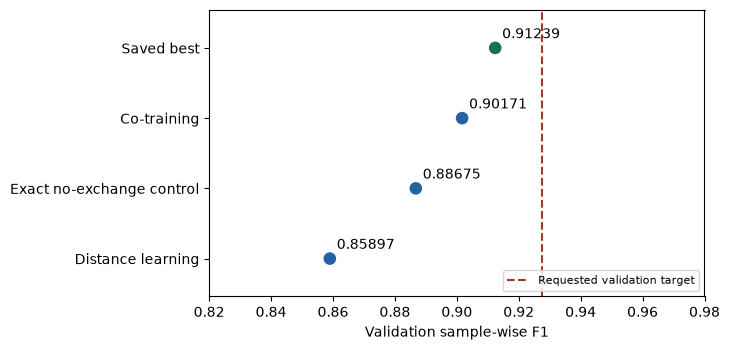

In [4]:
names=['Saved best','Co-training','Exact no-exchange control','Distance learning']
scores=[summary[k] for k in ['baseline_validation_f1','co_training_validation_f1','no_exchange_validation_f1','metric_validation_f1']]
fig,ax=plt.subplots(figsize=(7.4,3.6))
y=np.arange(len(names))
ax.scatter(scores,y,s=65,color=['#197144']+['#2563a0']*3)
for i,s in enumerate(scores):ax.annotate(f'{s:.5f}',(s,i),xytext=(5,7),textcoords='offset points')
ax.axvline(.92735,color='#9b3e27',linestyle='--',label='Requested validation target')
ax.set(yticks=y,yticklabels=names,xlim=(.82,.98),xlabel='Validation sample-wise F1')
ax.margins(y=.18);ax.invert_yaxis();ax.legend(loc='lower right',fontsize=8)
fig.tight_layout();fig.savefig(root/'figures/current_phase24_comparison.png',dpi=180)
plt.show()

## Integrity and reproducibility

Both approaches passed held-out-label perturbation, query-label/batch invariance, masked-duplicate exclusion and query-versus-masked-output consistency checks. Caches were cleared before perturbation to avoid masking leakage. With learned-distance weight zero, the metric model reproduced the original SVM scores to numerical precision.

Source files: `phase24.py`, `phase24_run.py`, `phase24_control.py` and `phase24_integrity.py`, all embedded in notebook 04. Configurations, policies, update diagnostics, predictions and results are under `experiments/phase24*`. The archive includes every unsuccessful trial.

References: [Blum and Mitchell's co-training paper](https://www.cs.cmu.edu/~avrim/Papers/cotrain.pdf) and [NCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NeighborhoodComponentsAnalysis.html).

In [5]:
json.loads((root/'experiments/phase24-integrity-checks.json').read_text())

{'checks': [{'model': 'co_training',
   'heldout_label_invariance': True,
   'query_label_invariance': True,
   'query_batch_invariance': True,
   'return_unlabeled_query_invariance': True,
   'masked_duplicates_excluded': True,
   'max_label_difference': 0.0,
   'max_batch_difference': 0.0},
  {'model': 'metric_ssl',
   'heldout_label_invariance': True,
   'query_label_invariance': True,
   'query_batch_invariance': True,
   'return_unlabeled_query_invariance': True,
   'masked_duplicates_excluded': True,
   'max_label_difference': 0.0,
   'max_batch_difference': 5.551115123125783e-17}],
 'caches_cleared_for_label_perturbation': True,
 'validation_fit': False,
 'source_sha256': {'phase24.py': '3baa7d6205211d7989fb801fb6d96461dc8f1f8cf143e811db99f8ec6fcb4217',
  'phase24_run.py': '699daa7a06a383c55b8cb723f60aa0a300aa588b0492bf621bfdec649b9c0f78'}}